# Pairs are not enough

A variogram, and every method built on it, describes a field through pairs of locations, how alike two
values are at a given separation. Much of what makes a field what it is involves more than two locations
at once, whether high values string together into channels, how a skewed variable clusters, which shapes
its patches take. An ensemble of partitions carries those relations in its cells, since a cell holds
three or more locations together. This tutorial shows, with two partition processes and with three
locations, what pairs can and cannot tell.

## Learning goals

- What the frequency with which two locations share a cell has to do with the variogram.
- How two partition processes can agree on every pair along one direction and differ for triples.
- Why a directional variogram reads the shape of the cells only along the direction chosen.
- Why, in general, the law of pairs does not fix the law of triples.
- How a map from the ensemble follows structure that a map from the variogram cannot.

*What does a variogram leave out?*

## The idea

Take a field built on a random partition, with one value, a *mark*, drawn independently for each cell,
the block-mark model of the theory Spatialize rests on ([The block-mark model](https://spatialize.readthedocs.io/en/latest/theory/blockmark.html)). Two locations have correlated values only when they
share a cell, so the covariance of the field at two locations is the variance of the marks times the
probability $e(v_1, v_2)$ that they share a cell, their **co-occurrence**. The third cumulant of three
locations is likewise the third cumulant of the marks times the probability $e(v_1, v_2, v_3)$ that all
three share a cell. Pairs fix the variogram. Triples fix the third order, which carries the asymmetry of
the field and the way its high values connect.

For the Mondrian process, whose cells are boxes cut at random, a set $S$ of locations shares a cell with
probability

$$e(S) = \exp\Big(-\sum_c \lambda_c\, \mathrm{range}_c(S)\Big),$$

with $\mathrm{range}_c(S)$ the extent of $S$ along axis $c$ and $\lambda_c$ the rate of cuts across that
axis. The theory Spatialize rests on illustrates this with two such processes, one with compact cells and one with cells
five times longer than wide, set to agree on every pair along $x$.

## Step by step

### Two processes that agree along x

Spatialize's Mondrian cuts every axis at one rate, $\lambda = 1/\big(\mu(D)(1 - \alpha)\big)$, with
$\mu(D)$ the sum of the sides of the data's box. Scaling the $y$ coordinate by 5 makes the cuts across
$y$ five times as frequent in the original units, so the cells come out five times longer along $x$ than
along $y$. Choosing $\alpha$ for the scaled coordinates so that $\lambda$ stays the same keeps the cuts
across $x$ as they were.

Which locations share a cell is read through the cell-mean decoder on 1 500 data with continuous values.
Two locations take the same cell mean exactly when they lie in one cell. Here cells without data must
stay empty, since a coarser cell would join locations the partition separates, so this tutorial sets
`empty_cells="nan"`, while the many data leave few cells empty.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.gs.esi import esi_nongriddata

spatialize.session.set(empty_cells="nan", progress=False)

rng = np.random.default_rng(0)
data = rng.random((1500, 2))
marks_of_data = rng.normal(size=1500)
stretch = np.array([1.0, 5.0])                     # the elongated process: y scaled by 5

mu = lambda p: np.ptp(p, axis=0).sum()             # the sum of the sides of the data's box
alpha_compact = 0.8
rate = 1 / (mu(data) * (1 - alpha_compact))
alpha_elongated = 1 - 1 / (mu(data * stretch) * rate)
print(f"rate {rate:.3f}, alpha {alpha_compact} compact, {alpha_elongated:.4f} elongated")

def cells(queries, elongated, n_partitions=4000, seed=0):
    # the cell mean of every query in every partition: equal values mean one cell
    s = stretch if elongated else np.ones(2)
    a = alpha_elongated if elongated else alpha_compact
    return esi_nongriddata(data * s, marks_of_data, queries * s, local_interpolator="cellmean", p_process="mondrian",
                           alpha=a, n_partitions=n_partitions, seed=seed).esi_samples()

def cooccurrence(points, elongated):
    m = cells(np.asarray(points, dtype=float), elongated)
    together = np.all(m == m[0], axis=0) & ~np.isnan(m[0])
    return together.mean()

closed = lambda points, elongated: np.exp(-rate * (np.ptp(points, axis=0) * (stretch if elongated else 1)).sum())

rows = {}
for h in (0.02, 0.05, 0.1, 0.2, 0.3):
    for axis, name in ((0, "along x"), (1, "along y")):
        pair = np.full((2, 2), 0.5); pair[0, axis] -= h / 2; pair[1, axis] += h / 2
        rows[name, h] = {"compact, measured": cooccurrence(pair, False), "compact, closed form": closed(pair, False),
                         "elongated, measured": cooccurrence(pair, True), "elongated, closed form": closed(pair, True)}
pd.DataFrame(rows).T.rename_axis(["direction", "separation"]).round(3)

rate 2.502, alpha 0.8 compact, 0.9333 elongated


,,"compact, measured","compact, closed form","elongated, measured","elongated, closed form"
direction,separation,,,,
along x,0.02,0.954,0.951,0.954,0.951
along y,0.02,0.948,0.951,0.776,0.779
along x,0.05,0.884,0.882,0.893,0.882
along y,0.05,0.884,0.882,0.535,0.535
along x,0.10,0.784,0.779,0.794,0.779
along y,0.10,0.773,0.779,0.288,0.286
along x,0.20,0.604,0.606,0.626,0.606
along y,0.20,0.597,0.606,0.078,0.082
along x,0.30,0.482,0.472,0.488,0.472


Along $x$ the two processes agree at every separation, both close to the closed form, the measured
values within about two hundredths of it. Along $y$ they part. At a separation of 0.1 two locations
share a compact cell 77 % of the time and an elongated one 29 %, as the closed form says, since the
elongated cells are thin across $y$.

### What a variogram sees

Fields drawn from each process, a mark per cell, make the same point as a practitioner would see it. The
variogram along $x$ and along $y$, averaged over 30 fields of each process, compares them one direction
at a time.

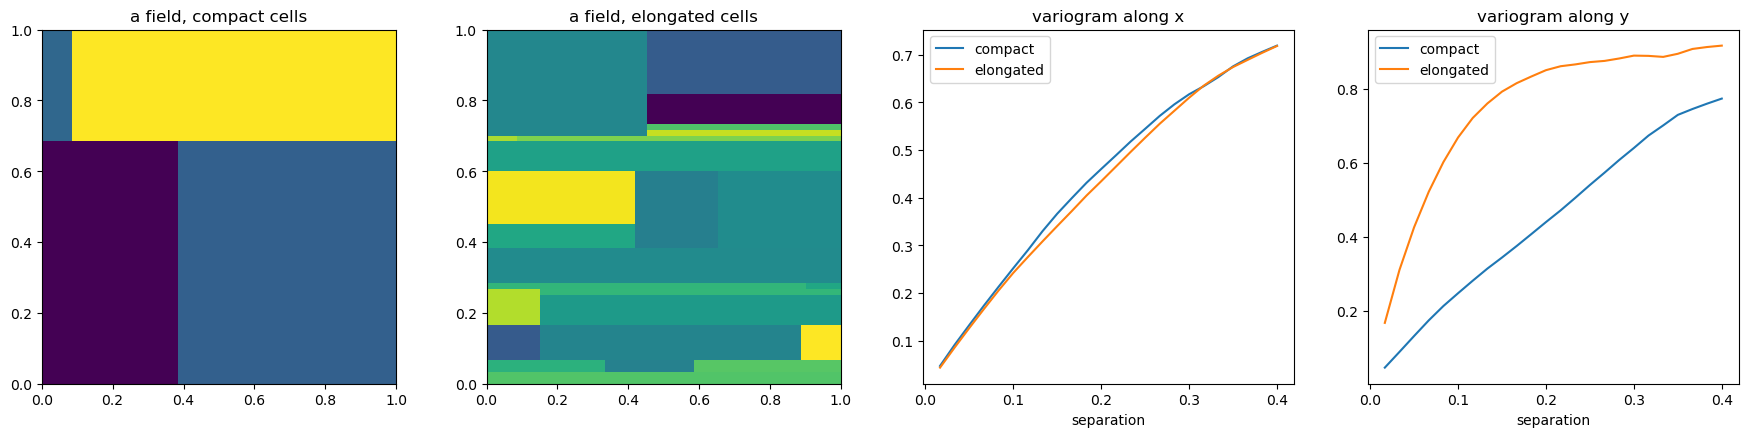

largest relative gap between the variograms, along x 0.08, along y 2.60


In [2]:
n = 60
grid = (np.arange(n) + 0.5) / n
nodes = np.stack(np.meshgrid(grid, grid, indexing="ij"), -1).reshape(-1, 2)

def fields(elongated, count=30):
    m = cells(nodes, elongated, n_partitions=count, seed=1)
    out = []
    for t in range(count):
        _, block = np.unique(m[:, t], return_inverse=True)
        out.append(np.random.default_rng(t).normal(size=block.max() + 1)[block].reshape(n, n))
    return np.stack(out)

def variogram(f, axis, lags):
    return np.array([0.5 * np.mean((np.take(f, range(h, n), axis=axis + 1) - np.take(f, range(0, n - h), axis=axis + 1)) ** 2)
                     for h in lags])

compact, elongated = fields(False), fields(True)
lags = np.arange(1, 25)
fig, axes = plt.subplots(1, 4, figsize=(22, 4.6))
axes[0].imshow(compact[0].T, origin="lower", cmap="viridis", extent=(0, 1, 0, 1)); axes[0].set_title("a field, compact cells")
axes[1].imshow(elongated[0].T, origin="lower", cmap="viridis", extent=(0, 1, 0, 1)); axes[1].set_title("a field, elongated cells")
for ax, axis, name in ((axes[2], 0, "along x"), (axes[3], 1, "along y")):
    ax.plot(lags / n, variogram(compact, axis, lags), label="compact")
    ax.plot(lags / n, variogram(elongated, axis, lags), label="elongated")
    ax.set_title(f"variogram {name}"); ax.set_xlabel("separation"); ax.legend()
plt.show()
gap = lambda axis: np.max(np.abs(variogram(compact, axis, lags) - variogram(elongated, axis, lags)) / variogram(compact, axis, lags))
print(f"largest relative gap between the variograms, along x {gap(0):.2f}, along y {gap(1):.2f}")

The compact cells are squat boxes, the elongated ones long strips along $x$. Along $x$ the two
variograms lie within 8 % of each other at every separation, so a study along that direction cannot tell
the processes apart. Along $y$ they differ by a factor of up to 3.6. A practitioner would read that as
anisotropy and fit one range per axis, which the second order can absorb.

### Triples

Three locations in a row along $x$, and three at the corners of a small triangle, ask the two processes
how often all three share a cell.

In [3]:
shapes = {"a row along x": [[0.40, 0.50], [0.50, 0.50], [0.60, 0.50]],
          "a triangle": [[0.45, 0.45], [0.55, 0.45], [0.50, 0.55]]}
pd.DataFrame({name: {"compact, measured": cooccurrence(p, False), "compact, closed form": closed(np.array(p), False),
                     "elongated, measured": cooccurrence(p, True), "elongated, closed form": closed(np.array(p), True)}
              for name, p in shapes.items()}).T.round(3)

,"compact, measured","compact, closed form","elongated, measured","elongated, closed form"
a row along x,0.604,0.606,0.626,0.606
a triangle,0.606,0.606,0.229,0.223


Three locations in a row along $x$ share a cell about 60 % of the time under both processes, since
their extent lies along the direction where the processes agree. The triangle, whose extent reaches
across $y$, shares a compact cell 61 % of the time and an elongated one 23 %. The triangle reads the shape
of the cells without a direction being chosen, while a pair reads it only along the direction it is
laid.

### Pairs never fix triples

Within the Mondrian family the rates fix every co-occurrence, so knowing the pairs in every direction
would settle the triples too. That is a property of one family. In general the law of pairs leaves the
triples free. The theory shows it with three locations and two partition laws.

- The first puts all three in one cell half of the time and each alone otherwise.
- The second puts each pair together, the third location apart, a quarter of the time each, and all
  three together the remaining quarter.

In both, every pair shares a cell half of the time, while all three share one half of the time under the
first law and a quarter under the second. Marks with a skewed law, an exponential centred at zero, make
the consequence visible. The covariances agree, while the third moment, the mean of the product of the
three values, halves.

In [4]:
rng = np.random.default_rng(2)
draws = 400_000
groupings = {"first law": ([[0, 0, 0], [0, 1, 2]], [0.5, 0.5]),
             "second law": ([[0, 0, 1], [0, 1, 0], [1, 0, 0], [0, 0, 0]], [0.25, 0.25, 0.25, 0.25])}
rows = {}
for name, (labels, weights) in groupings.items():
    which = rng.choice(len(labels), size=draws, p=weights)
    block = np.array(labels)[which]                                  # [draw, location] block of each location
    marks = rng.exponential(size=(draws, 3)) - 1.0                   # mean 0, variance 1, third cumulant 2
    z = np.take_along_axis(marks, block, axis=1)
    rows[name] = {"pair (1, 2) shares a cell": np.mean(block[:, 0] == block[:, 1]),
                  "all three share a cell": np.mean((block[:, 0] == block[:, 1]) & (block[:, 1] == block[:, 2])),
                  "covariance of locations 1 and 2": np.mean(z[:, 0] * z[:, 1]),
                  "covariance of locations 1 and 3": np.mean(z[:, 0] * z[:, 2]),
                  "third moment E[Z1 Z2 Z3]": np.mean(z[:, 0] * z[:, 1] * z[:, 2])}
pd.DataFrame(rows).T.round(3)

,"pair (1, 2) shares a cell",all three share a cell,covariance of locations 1 and 2,covariance of locations 1 and 3,third moment E[Z1 Z2 Z3]
first law,0.500,0.500,0.495,0.496,0.972
second law,0.501,0.251,0.495,0.500,0.484


Both laws put each pair in one cell half of the time, so their covariances agree, 0.5 up to the noise
of the simulation. All three share a cell half of the time under the first law and a quarter under the
second. The third moment follows, 0.97 against 0.48, the third cumulant of the marks, 2, times the
probability of the triple. Two fields with the same variogram can therefore differ in skewness, and in
the way their high values gather, as much as these two do.

### Maps beyond the second order

The same point reaches the maps. A field of four sinuous channels, high values across a low background,
has a variogram. A second field with exactly that variogram follows from keeping the amplitudes of the
first field's Fourier transform and drawing its phases at random, which keeps every pair statistic and
destroys the channels. Kriging, which sees the data through the variogram, has nothing to tell the two
apart by. We sample both at the same 400 locations and estimate each with ordinary kriging from PyKrige
and with Spatialize, each with the settings five-fold cross-validation prefers.

In [5]:
from pykrige.rk import Krige
from scipy import ndimage
from sklearn.model_selection import GridSearchCV
from spatialize.evaluation import SuppressOutput, kriging_prediction
from spatialize.gs.esi import esi_pareto_hparams_search
import spatialize.gs.esi.scoring as sc

spatialize.session.set(empty_cells="coarsen")
pd.set_option("display.max_colwidth", None)
m = 100
cells_ = (np.arange(m) + 0.5) / m
X, Y = np.meshgrid(cells_, cells_, indexing="ij")
grid_nodes = np.stack([X.ravel(), Y.ravel()], -1)
rng = np.random.default_rng(0)
inside = np.zeros((m, m), bool)
for _ in range(4):
    centre, amplitude, wavelength = rng.uniform(.1, .9), rng.uniform(.04, .12), rng.uniform(.3, .7)
    phase, width = rng.uniform(0, 6.3), rng.uniform(.025, .04)
    inside |= np.abs(Y - (centre + amplitude * np.sin(2 * np.pi * X / wavelength + phase))) < width
channel_field = np.where(inside, rng.lognormal(1.0, 0.25, (m, m)), rng.lognormal(-0.5, 0.25, (m, m)))
spectrum = np.abs(np.fft.fft2(channel_field - channel_field.mean()))
phases = np.angle(np.fft.fft2(rng.standard_normal((m, m))))
twin = np.real(np.fft.ifft2(spectrum * np.exp(1j * phases))) + channel_field.mean()
truths = {"channels": channel_field.ravel(), "same variogram": twin.ravel()}

def directional(z, axis, lags=range(1, 30)):
    z = z.reshape(m, m)
    return np.array([0.5 * np.mean((np.take(z, range(h, m), axis=axis) - np.take(z, range(0, m - h), axis=axis)) ** 2) for h in lags])
pd.DataFrame({name: {"variogram at 0.05, along x": directional(z, 0)[4], "at 0.05, along y": directional(z, 1)[4],
                     "at 0.20, along x": directional(z, 0)[19], "at 0.20, along y": directional(z, 1)[19],
                     "skewness": pd.Series(z).skew()} for name, z in truths.items()}).T.round(3)

,"variogram at 0.05, along x","at 0.05, along y","at 0.20, along x","at 0.20, along y",skewness
channels,0.664,0.909,0.985,1.196,1.464
same variogram,0.653,0.860,0.956,1.138,0.074


In [6]:
def kfold(points, values, predict, k=5):
    folds = np.random.default_rng(0).permutation(len(values)) % k
    out = np.empty(len(values))
    for f in range(k):
        test = folds == f
        out[test] = predict(points[~test], values[~test], points[test])
    return np.mean(np.abs(out - values))

def kriging(points, values):
    search = GridSearchCV(Krige(), {"variogram_model": ["spherical", "exponential", "gaussian"], "nlags": [8],
                                    "n_closest_points": [10, 20], "method": ["ordinary"]}, scoring="neg_mean_absolute_error", cv=5)
    with SuppressOutput():
        params = search.fit(points, values).best_params_
    return (lambda x: kriging_prediction(points, values, x, **params),
            f"ordinary kriging, {params['variogram_model']} variogram, {params['n_closest_points']} neighbours")

def ensemble(points, values):
    best, best_error = None, np.inf
    for p_process, decoder in (("mondrian", "adaptiveidw"), ("mondrian", "sharpidw"), ("voronoi", "sharpidw")):
        knee = esi_pareto_hparams_search(points, values, local_interpolator=decoder, p_process=p_process, n_partitions=[100],
                                         alpha=[0.8, 0.9, 0.95, 0.98], k=5, scoring=sc.mae, seed=0).best_result(strategy="knee")
        if knee["decoder_error"] < best_error:
            best, best_error = dict(local_interpolator=decoder, p_process=p_process, alpha=knee["alpha"]), knee["decoder_error"]
    readings = {"mean": lambda s: s.mean(axis=1), "median": lambda s: np.median(s, axis=1)}
    run = lambda p, v, x, r: readings[r](esi_nongriddata(p, v, x, n_partitions=200, seed=0, **best).esi_samples())
    reading = min(readings, key=lambda r: kfold(points, values, lambda p, v, x: run(p, v, x, r)))
    return (lambda x: run(points, values, x, reading),
            f"{best['p_process']}, {best['local_interpolator']}, alpha {best['alpha']}, {reading} of the members")

pick = np.random.default_rng(1).choice(m * m, 400, replace=False)
threshold = (np.median(channel_field[inside]) + np.median(channel_field[~inside])) / 2
estimates, rows, recipes = {}, {}, {}
for name, truth in truths.items():
    for method, build in (("kriging", kriging), ("Spatialize", ensemble)):
        predict, recipes[name, method] = build(grid_nodes[pick], truth[pick])
        z = np.asarray(predict(grid_nodes), dtype=float)
        estimates[name, method] = z
        high, true_high = z > threshold, truth > threshold
        rows[name, method] = {"settings": recipes[name, method], "MAE against the truth": np.abs(z - truth).mean(),
                              "overlap with the true high region": (high & true_high).sum() / max((high | true_high).sum(), 1),
                              "pieces of the high region": ndimage.label(high.reshape(m, m))[1]}
print(f"the channels: {ndimage.label(inside)[1]} connected pieces")
pd.DataFrame(rows).T.infer_objects().round(3)

the channels: 2 connected pieces


settings  \
channels       kriging        ordinary kriging, spherical variogram, 10 neighbours   
               Spatialize  mondrian, adaptiveidw, alpha 0.9, median of the members   
same variogram kriging      ordinary kriging, exponential variogram, 10 neighbours   
               Spatialize  mondrian, adaptiveidw, alpha 0.9, median of the members   

                           MAE against the truth  \
channels       kriging                     0.603   
               Spatialize                  0.465   
same variogram kriging                     0.680   
               Spatialize                  0.636   

                           overlap with the true high region  \
channels       kriging                                 0.463   
               Spatialize                              0.621   
same variogram kriging                                 0.262   
               Spatialize                              0.379   

                           pieces of the high region  
channels       kriging                            25  
               Spatialize                          9  
same variogram kriging                            83  
               Spatialize                         45

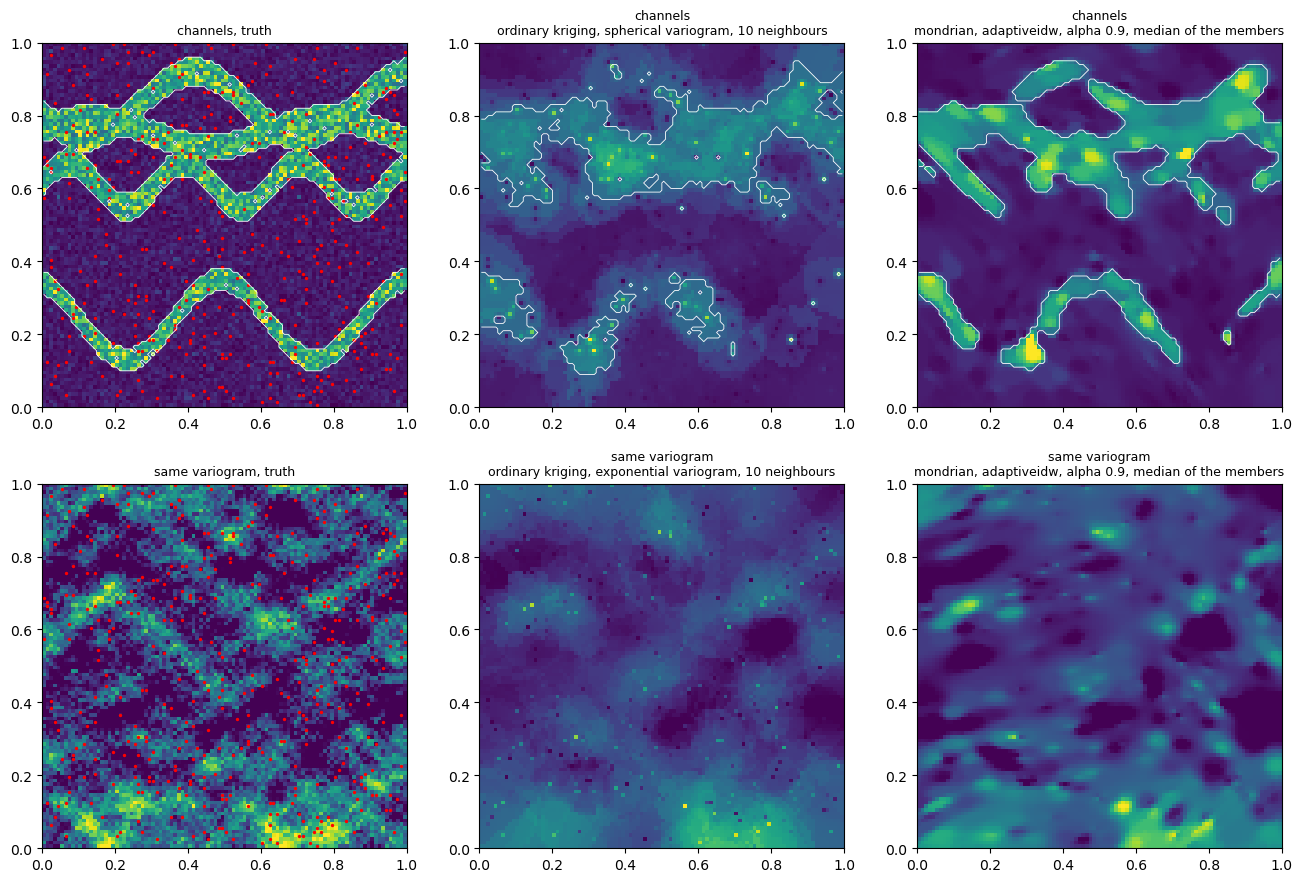

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
lo, hi = np.percentile(channel_field, [1, 99])
for row, (name, truth) in enumerate(truths.items()):
    for col, (title, z) in enumerate((("truth", truth), ("kriging", estimates[name, "kriging"]), ("Spatialize", estimates[name, "Spatialize"]))):
        ax = axes[row, col]
        ax.imshow(z.reshape(m, m).T, origin="lower", cmap="viridis", vmin=lo, vmax=hi, extent=(0, 1, 0, 1))
        if name == "channels":
            ax.contour(cells_, cells_, (z > threshold).reshape(m, m).T.astype(float), levels=[0.5], colors="white", linewidths=0.6)
        ax.set_title(f"{name}, truth" if title == "truth" else f"{name}\n{recipes[name, title]}", fontsize=9)
for ax in axes[:, 0]:
    ax.scatter(grid_nodes[pick, 0], grid_nodes[pick, 1], s=2, c="red")
plt.show()

The two fields have the same variogram, within a few hundredths at every distance and in both
directions, while their laws differ, the channel field skewed at 1.46 and its twin symmetric. Kriging
treats them alike, with errors of 0.60 and 0.68, and in both draws blurred patches, which on the channel
field break into 25 pieces. Spatialize follows what the variogram leaves out. On the channel field its
error is 0.465, 23 % below kriging's, and its high region traces the channels as sinuous bodies in 9
pieces. On the twin, which has no channels to follow, it gains only 6.5 % over kriging. The difference
between the two gains is the structure beyond pairs that the partitions read and the variogram does not.

### Samples along the channels

Sampling is rarely uniform. A survey follows the features it is after, wells along a river, sensors
along roads, drilling along a vein. Here 300 of the 400 samples fall inside the channels and 100 outside,
a design that tells the ensemble a great deal about the channels and little about the background.

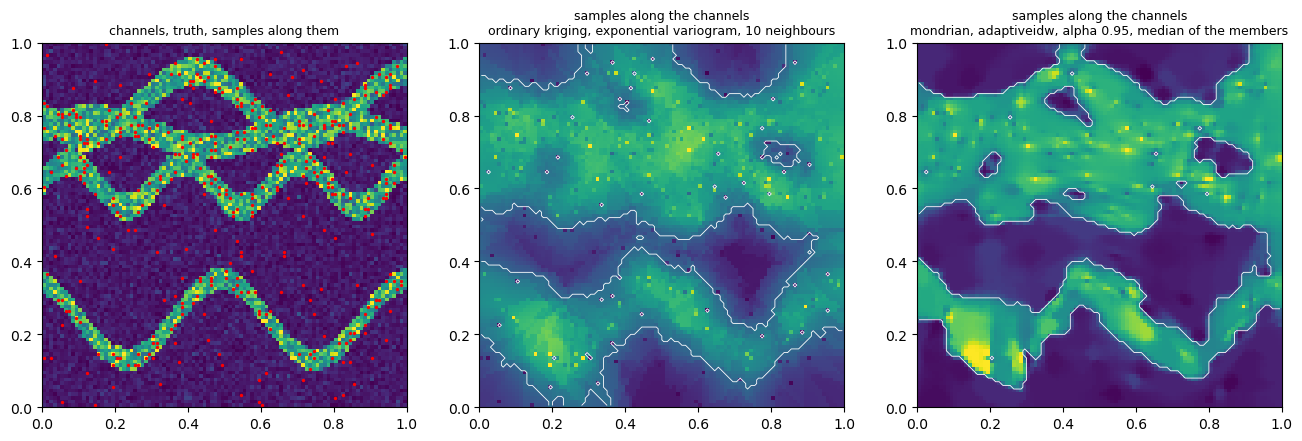

,settings,MAE against the truth,overlap with the true high region,pieces of the high region
kriging,"ordinary kriging, exponential variogram, 10 neighbours",0.963,0.400,6
Spatialize,"mondrian, adaptiveidw, alpha 0.95, median of the members",0.727,0.509,1


In [8]:
inside_nodes, outside_nodes = np.flatnonzero(inside.ravel()), np.flatnonzero(~inside.ravel())
draw = np.random.default_rng(2)
along = np.concatenate([draw.choice(inside_nodes, 300, replace=False), draw.choice(outside_nodes, 100, replace=False)])
truth = truths["channels"]
along_estimates, rows = {}, {}
for method, build in (("kriging", kriging), ("Spatialize", ensemble)):
    predict, recipe = build(grid_nodes[along], truth[along])
    z = np.asarray(predict(grid_nodes), dtype=float)
    along_estimates[method] = (z, recipe)
    high = z > threshold
    rows[method] = {"settings": recipe, "MAE against the truth": np.abs(z - truth).mean(),
                    "overlap with the true high region": (high & inside.ravel()).sum() / (high | inside.ravel()).sum(),
                    "pieces of the high region": ndimage.label(high.reshape(m, m))[1]}
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
axes[0].imshow(truth.reshape(m, m).T, origin="lower", cmap="viridis", vmin=lo, vmax=hi, extent=(0, 1, 0, 1))
axes[0].scatter(grid_nodes[along, 0], grid_nodes[along, 1], s=2, c="red"); axes[0].set_title("channels, truth, samples along them", fontsize=9)
for ax, (method, (z, recipe)) in zip(axes[1:], along_estimates.items()):
    ax.imshow(z.reshape(m, m).T, origin="lower", cmap="viridis", vmin=lo, vmax=hi, extent=(0, 1, 0, 1))
    ax.contour(cells_, cells_, (z > threshold).reshape(m, m).T.astype(float), levels=[0.5], colors="white", linewidths=0.6)
    ax.set_title(f"samples along the channels\n{recipe}", fontsize=9)
plt.show()
pd.DataFrame(rows).T.infer_objects().round(3)

Both maps widen the channels, since the background between them holds a quarter of the samples and its
estimates lean towards the channel values. Kriging draws a broad belt across the upper half and blobs
below it, an error of 0.96 and an overlap of 0.40 with the true channels. Spatialize follows the lower
channel along its whole sinuous course and draws the two upper channels as one band, with holes where
the gaps between their crossings lie, an error of 0.73 and an overlap of 0.51. Its high region joins
into one piece at the western edge, where the truth has two, so the count of pieces flatters it here.
The partitions read the shape of a channel from where its samples lie, which a variogram of samples
taken mostly inside the channels has no way to express.

## Pitfalls

- **Choosing the encoder from a variogram.** Mondrian and Voronoi partitions, or one partition at two
  shapes of cell, can give close variograms along a direction while grouping three or more locations
  differently. Compare encoders by their cross-validated error and by the readings that involve many
  locations at once.
- **Scaling a coordinate without adjusting the granularity.** Spatialize sets its rate from the sides of
  the data's box, so stretching one axis changes the rate along the others too. Choose `alpha` for the
  scaled coordinates, as here, or let the Pareto search choose it.
- **Reading co-occurrences with coarsened cells.** Under `empty_cells="coarsen"` a location in an empty
  cell takes the value of a larger cell, which joins locations the partition separates. Read
  co-occurrences under `"nan"`, with enough data to leave few cells empty.
- **The members' law taken as second-order.** The members of an ensemble share cells by threes and more,
  so their joint law carries the triples of the encoder. Readings over many locations, an area or a
  connected path, depend on it.

## Try it yourself

1. Replace the elongated process by Voronoi cells (`p_process="voronoi"`) and compare the pairs along x.
2. Measure the triangle at three sizes and plot the logarithm of its co-occurrence against its size.
3. In the three-location example, use normal marks and watch the third moments of both laws vanish.

## Next

- *Encoders, Mondrian or Voronoi*, for the co-occurrence of each process.
- *The variogram as an inference*, for what the ensemble recovers of a variogram.
- *Beyond the classical interpolators*, for the same contrast on more fields.
- *Estimating categories*, for what categories leave identifiable beyond pairs.
- The documentation's [Encoders](https://spatialize.readthedocs.io/en/latest/theory/encoders.html) and
  [The block-mark model](https://spatialize.readthedocs.io/en/latest/theory/blockmark.html) (theory).